# RQ1 & RQ2 Analysis: Detectability of LLM-Generated PR Descriptions

- Omits confusion matrix heatmaps.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from scipy.stats import chi2_contingency, kruskal, norm
import scikit_posthocs as sp
import itertools

# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## Helper Functions


In [2]:
# Cliff's Delta Implementation
def cliffs_delta(lst1, lst2):
    """Compute Cliff's Delta effect size."""
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

def accuracy_variance(p, n):
    """Binomial variance of accuracy estimate p over n samples."""
    if n <= 0:
        return 0.0
    return (p * (1 - p)) / n

def wilson_ci(successes, n, z=1.96):
    """Wilson score interval for a proportion."""
    if n == 0:
        return (0.0, 0.0)
    p = successes / n
    denom = 1 + (z ** 2) / n
    center = (p + (z ** 2) / (2 * n)) / denom
    margin = (z / denom) * np.sqrt((p * (1 - p) / n) + ((z ** 2) / (4 * n ** 2)))
    return (max(0.0, center - margin), min(1.0, center + margin))

def cramers_v_from_table(table):
    """Cramer's V for an RxC contingency table."""
    chi2, _, _, _ = chi2_contingency(table)
    table = np.asarray(table)
    n = table.sum()
    if n == 0:
        return 0.0
    r, c = table.shape
    k = min(r - 1, c - 1)
    if k <= 0:
        return 0.0
    return np.sqrt(chi2 / (n * k))

def two_proportion_ztest(correct_1, n_1, correct_2, n_2):
    """Two-sided z-test for difference in two independent proportions."""
    if n_1 == 0 or n_2 == 0:
        return 0.0, 1.0
    p1 = correct_1 / n_1
    p2 = correct_2 / n_2
    pooled = (correct_1 + correct_2) / (n_1 + n_2)
    se = np.sqrt(pooled * (1 - pooled) * ((1 / n_1) + (1 / n_2)))
    if se == 0:
        return 0.0, 1.0
    z_stat = (p1 - p2) / se
    p_val = 2 * (1 - norm.cdf(abs(z_stat)))
    return z_stat, p_val

def calculate_metrics(y_true, y_pred):
    """Compute accuracy, precision, recall, F1, and specificity."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'Specificity': specificity
    }

## 1. Data Loading & Preparation


In [3]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'

df = pd.read_csv(csv_path)

# Only roberta detectors
tools = ['roberta', 'roberta-qa', 'zerogpt']

for tool in tools:
    col = f'{tool}_is_ai'
    if col in df.columns:
        df[col] = df[col].replace({'TRUE': True, 'FALSE': False, 'True': True, 'False': False})
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# Human and AI entries already share the same GraphQL pr_id format
df['normalized_pr_id'] = df['pr_id'].astype(str)

# Map Variation Codes to Names
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff', # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents' 
}

df['Context_Name'] = df['variation'].map(variation_map)

# --- FILTERING STEP ---
# Identify PRs that have generated AI counterparts
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())

# We only want humans that exist in the AI set
valid_ids = ai_pr_ids.intersection(human_pr_ids)

# Filter Human DF to only those with counterparts
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['true_label'] = 0
human_df['model'] = 'Human' 

# Also create filtered AI subset for convenience
ai_subset_full = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_subset_full['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_subset_full)}")

Paired PR Count: 308
Models found: <StringArray>
['meta-llama/llama-3.1-70b-instruct',             'gpt-5-mini-2025-08-07',
         'Qwen/Qwen2.5-72B-Instruct']
Length: 3, dtype: str
Human entries: 308, AI entries: 5528


## 0. Detection Failures


In [4]:
import json as _json

# --- Failure Analysis ---
failure_rows = []
for tool in tools:
    success_col = f'{tool}_success'
    resp_col = f'{tool}_response'
    
    failed = df[df[success_col] == False]
    total = len(df)
    
    # Parse error reasons from response JSON
    reasons = {}
    for resp in failed[resp_col].dropna():
        try:
            d = _json.loads(str(resp).replace("'", '"'))
            reason = d.get('error', 'unknown')
        except Exception:
            reason = str(resp)[:80]
        reasons[reason] = reasons.get(reason, 0) + 1
    
    for reason, count in sorted(reasons.items(), key=lambda x: -x[1]):
        failure_rows.append({
            'Detector': tool,
            'Failure Reason': reason,
            'Count': count,
            'Pct of Total': f"{count / total * 100:.1f}%"
        })

failure_summary = pd.DataFrame(failure_rows)
print(f"Total entries: {len(df)}")
display(failure_summary)

# Breakdown by model and entry type — per detector
for tool in tools:
    failed = df[df[f'{tool}_success'] == False]
    
    print(f"\nFailures by Model ({tool}):")
    failed_by_model = failed.groupby('model').size().reset_index(name='Failed Count')
    failed_by_model = failed_by_model.sort_values('Failed Count', ascending=False)
    display(failed_by_model)
    
    print(f"\nFailures by Entry Type ({tool}):")
    failed_by_type = failed.groupby('entry_type').size().reset_index(name='Failed Count')
    display(failed_by_type)


Total entries: 5836


,Detector,Failure Reason,Count,Pct of Total
0,roberta,Text too short,1201,20.6%
1,roberta-qa,Text too short,1201,20.6%



Failures by Model (roberta):


,model,Failed Count
3,meta-llama/llama-3.1-70b-instruct,1023
0,Qwen/Qwen2.5-72B-Instruct,130
2,human,45
1,gpt-5-mini-2025-08-07,3



Failures by Entry Type (roberta):


,entry_type,Failed Count
0,ai,1156
1,human,45


... (4 outputs left out)


Failures by Model (zerogpt):


,model,Failed Count



Failures by Entry Type (zerogpt):


,entry_type,Failed Count


## 2. RQ1 — Baseline Detection by LLM (P-3)



--- RQ1 by LLM (P-3): Metrics + Variance ---


,Accuracy,Precision,Recall,F1-Score,Specificity,Tool,Model,N,Correct,Accuracy Variance,Accuracy SE,Accuracy 95% CI
0,0.600649,1.0,0.201299,0.335135,1.0,roberta,Qwen/Qwen2.5-72B-Instruct,616,370,0.000389,0.019733,"[0.561, 0.639]"
1,0.709416,1.0,0.418831,0.590389,1.0,roberta-qa,Qwen/Qwen2.5-72B-Instruct,616,437,0.000335,0.018293,"[0.672, 0.744]"
2,0.719156,1.0,0.438312,0.609481,1.0,zerogpt,Qwen/Qwen2.5-72B-Instruct,616,443,0.000328,0.018107,"[0.682, 0.753]"
3,0.503247,1.0,0.006494,0.012903,1.0,roberta,gpt-5-mini-2025-08-07,616,310,0.000406,0.020145,"[0.464, 0.543]"
4,0.500000,0.0,0.000000,0.000000,1.0,roberta-qa,gpt-5-mini-2025-08-07,616,308,0.000406,0.020146,"[0.461, 0.539]"
5,0.550325,1.0,0.100649,0.182891,1.0,zerogpt,gpt-5-mini-2025-08-07,616,339,0.000402,0.020043,"[0.511, 0.589]"
6,0.543831,1.0,0.087662,0.161194,1.0,roberta,meta-llama/llama-3.1-70b-instruct,616,335,0.000403,0.020068,"[0.504, 0.583]"
7,0.540584,1.0,0.081169,0.150150,1.0,roberta-qa,meta-llama/llama-3.1-70b-instruct,616,333,0.000403,0.020079,"[0.501, 0.580]"
8,0.506494,1.0,0.012987,0.025641,1.0,zerogpt,meta-llama/llama-3.1-70b-instruct,616,312,0.000406,0.020144,"[0.467, 0.546]"


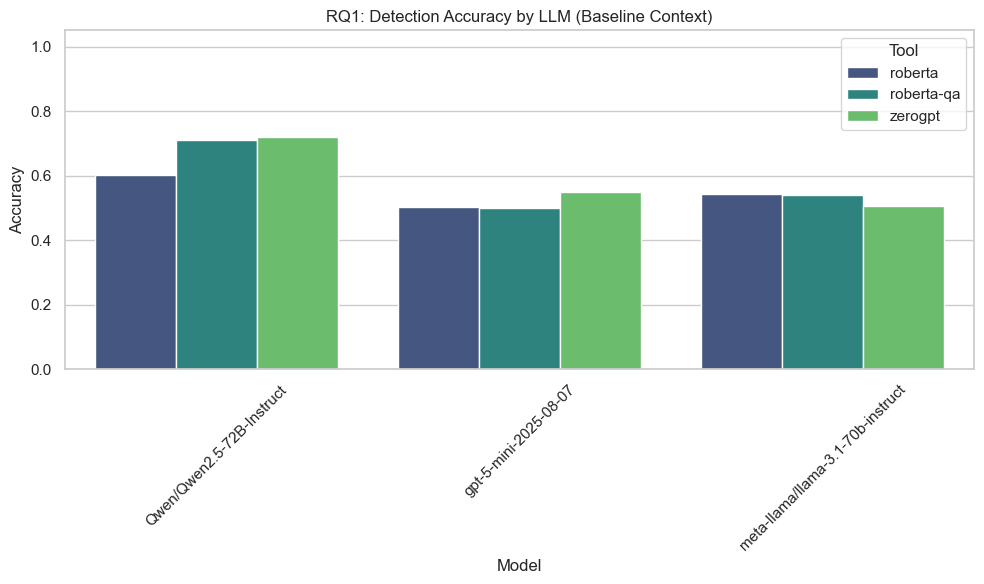

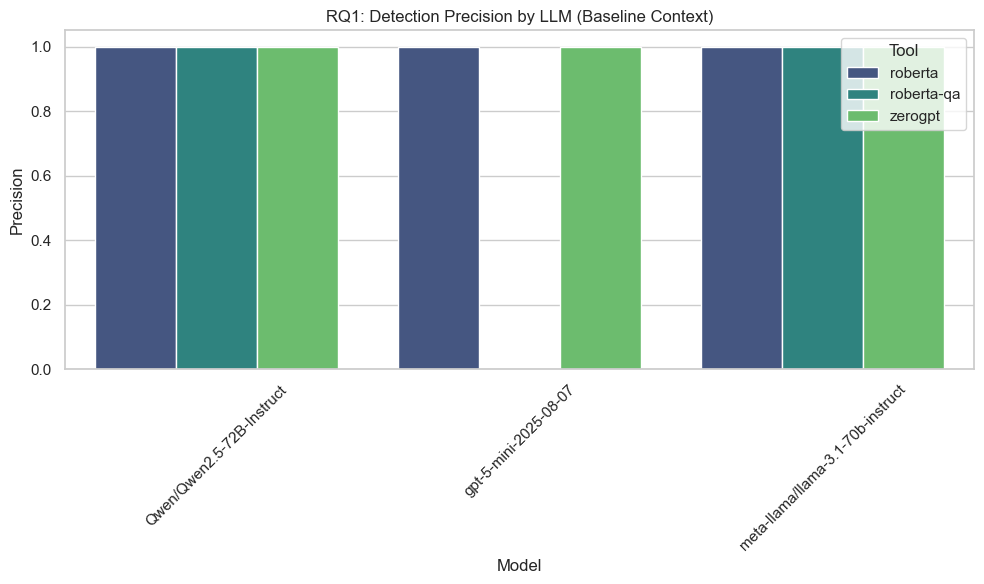

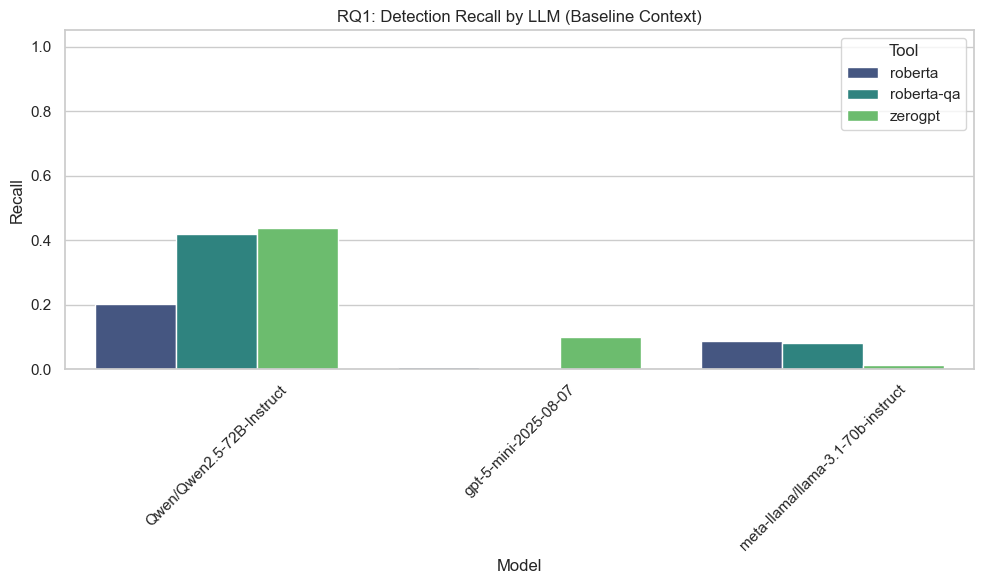

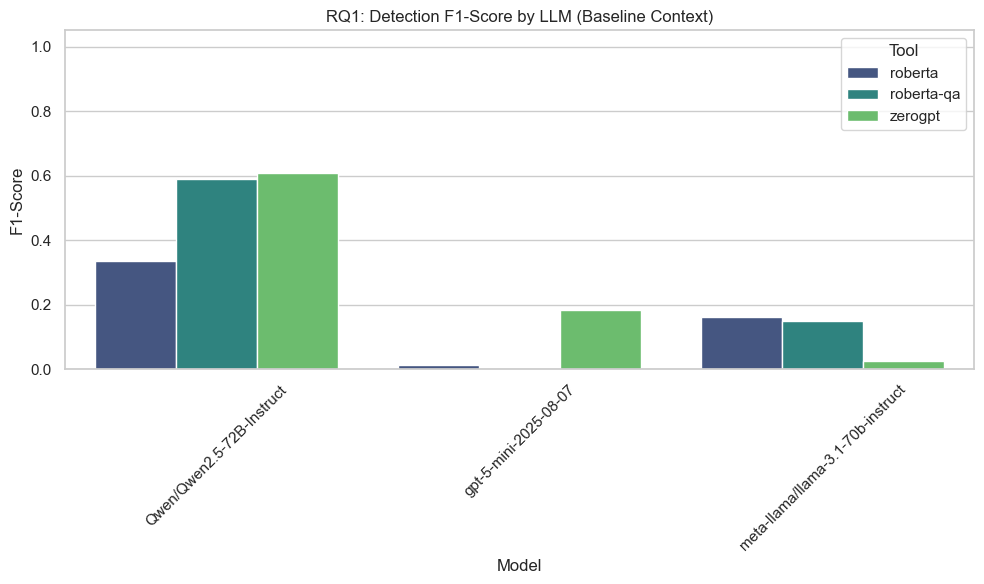

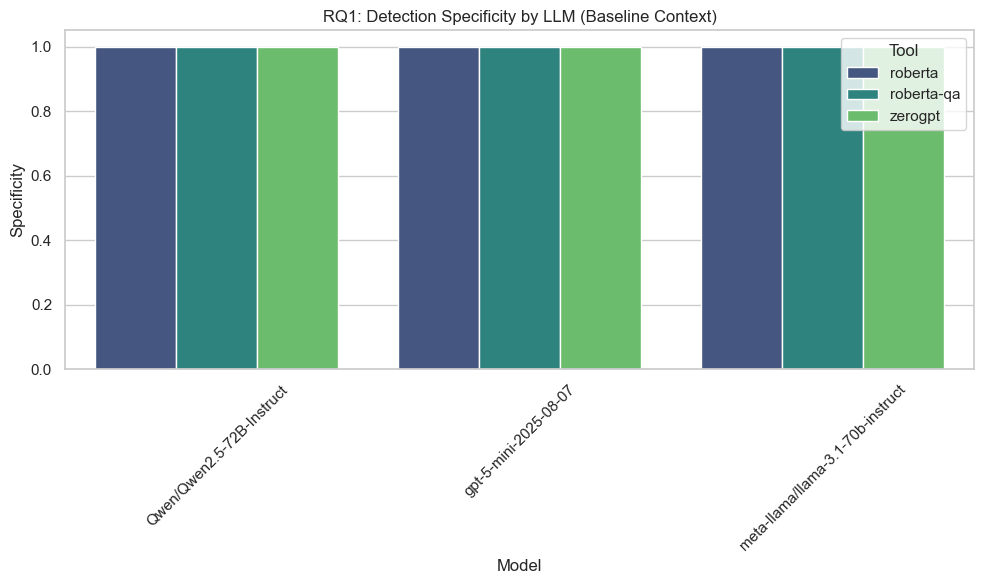

In [5]:
# Overall Baseline (P-3)
ai_p3_df = ai_subset_full[ai_subset_full['variation'] == 'P-3'].copy()
ai_p3_df['true_label'] = 1

# Breakdown by LLM
print("\n--- RQ1 by LLM (P-3): Metrics + Variance ---")
llm_results = []
rq1_accuracy_records = []
models = sorted(ai_p3_df['model'].unique())

for model in models:
    # Select only this model's AI outputs + all paired Humans
    model_ai = ai_p3_df[ai_p3_df['model'] == model]
    model_combined = pd.concat([human_df, model_ai], ignore_index=True)
    n_total = len(model_combined)

    for tool in tools:
        y_true = model_combined['true_label']
        y_pred = model_combined[f'{tool}_is_ai']
        m = calculate_metrics(y_true, y_pred)

        # Variance and interval for baseline accuracy
        correct = int((y_true == y_pred).sum())
        acc = m['Accuracy']
        acc_var = accuracy_variance(acc, n_total)
        acc_se = np.sqrt(acc_var)
        ci_low, ci_high = wilson_ci(correct, n_total)

        m['Tool'] = tool
        m['Model'] = model
        m['N'] = n_total
        m['Correct'] = correct
        m['Accuracy Variance'] = acc_var
        m['Accuracy SE'] = acc_se
        m['Accuracy 95% CI'] = f"[{ci_low:.3f}, {ci_high:.3f}]"
        llm_results.append(m)

        rq1_accuracy_records.append({
            'Tool': tool,
            'Model': model,
            'Correct': correct,
            'N': n_total,
            'Accuracy': acc,
            'Accuracy Variance': acc_var
        })

llm_metrics_df = pd.DataFrame(llm_results)
display(llm_metrics_df)

# Visualization: All Metrics (Separately)
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Specificity']
for metric in metrics_to_plot:
    plt.figure(figsize=(10, 6))
    sns.barplot(data=llm_metrics_df, x='Model', y=metric, hue='Tool', palette='viridis')
    plt.title(f'RQ1: Detection {metric} by LLM (Baseline Context)')
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 3. RQ1 — Significance + Variance Reporting (Baseline P-3)

- Omnibus significance: Chi-square test of accuracy by model (per detector).
- Effect size: Cramer's V.
- Post-hoc: Pairwise two-proportion z-tests with Bonferroni correction.
- Variance: Per-model accuracy variance, SE/95% CI reported in the RQ1 table.

In [6]:
print("--- RQ1 Significance: Accuracy vs Model (Baseline P-3) ---")

for tool in tools:
    contingency_table = []
    per_model_stats = []

    for model in models:
        model_ai = ai_p3_df[ai_p3_df['model'] == model]
        model_combined = pd.concat([human_df, model_ai], ignore_index=True)

        y_true = model_combined['true_label']
        y_pred = model_combined[f'{tool}_is_ai']
        correct = int((y_true == y_pred).sum())
        incorrect = int((y_true != y_pred).sum())
        n = correct + incorrect
        acc = correct / n if n > 0 else 0.0
        var = accuracy_variance(acc, n)

        contingency_table.append([correct, incorrect])
        per_model_stats.append({
            'Model': model,
            'Correct': correct,
            'Incorrect': incorrect,
            'N': n,
            'Accuracy': acc,
            'Accuracy Variance': var
        })

    chi2, p, dof, expected = chi2_contingency(contingency_table)
    cramer_v = cramers_v_from_table(contingency_table)
    significance = "Significant (p < 0.05)" if p < 0.05 else "Not Significant"

    print(f"\nTool: {tool}")
    print(f"  Omnibus Chi2({dof}) = {chi2:.4f}")
    print(f"  P-Value: {p:.4e} -> {significance}")
    print(f"  Effect Size (Cramer's V): {cramer_v:.4f}")

    model_stats_df = pd.DataFrame(per_model_stats)
    display(model_stats_df)

    # Pairwise post-hoc on accuracy proportions with Bonferroni correction
    pairwise_rows = []
    pairs = list(itertools.combinations(per_model_stats, 2))
    m_tests = max(1, len(pairs))

    for a, b in pairs:
        z_stat, raw_p = two_proportion_ztest(a['Correct'], a['N'], b['Correct'], b['N'])
        p_adj = min(1.0, raw_p * m_tests)
        pairwise_rows.append({
            'Comparison': f"{a['Model']} vs {b['Model']}",
            'z-stat': z_stat,
            'raw p-value': raw_p,
            'bonferroni p-value': p_adj,
            'Significant (adj p < 0.05)': p_adj < 0.05
        })

    if pairwise_rows:
        pairwise_df = pd.DataFrame(pairwise_rows).sort_values('bonferroni p-value')
        display(pairwise_df)

--- RQ1 Significance: Accuracy vs Model (Baseline P-3) ---

Tool: roberta
  Omnibus Chi2(2) = 11.9121
  P-Value: 2.5902e-03 -> Significant (p < 0.05)
  Effect Size (Cramer's V): 0.0803


,Model,Correct,Incorrect,N,Accuracy,Accuracy Variance
0,Qwen/Qwen2.5-72B-Instruct,370,246,616,0.600649,0.000389
1,gpt-5-mini-2025-08-07,310,306,616,0.503247,0.000406
2,meta-llama/llama-3.1-70b-instruct,335,281,616,0.543831,0.000403


,Comparison,z-stat,raw p-value,bonferroni p-value,Significant (adj p < 0.05)
0,Qwen/Qwen2.5-72B-Instruct vs gpt-5-mini-2025-0...,3.437420,0.000587,0.001762,True
1,Qwen/Qwen2.5-72B-Instruct vs meta-llama/llama-...,2.015457,0.043857,0.131570,False
2,gpt-5-mini-2025-08-07 vs meta-llama/llama-3.1-...,-1.426088,0.153843,0.461528,False



Tool: roberta-qa
  Omnibus Chi2(2) = 62.5202
  P-Value: 2.6540e-14 -> Significant (p < 0.05)
  Effect Size (Cramer's V): 0.1839


,Model,Correct,Incorrect,N,Accuracy,Accuracy Variance
0,Qwen/Qwen2.5-72B-Instruct,437,179,616,0.709416,0.000335
1,gpt-5-mini-2025-08-07,308,308,616,0.500000,0.000406
2,meta-llama/llama-3.1-70b-instruct,333,283,616,0.540584,0.000403


,Comparison,z-stat,raw p-value,bonferroni p-value,Significant (adj p < 0.05)
0,Qwen/Qwen2.5-72B-Instruct vs gpt-5-mini-2025-0...,7.517137,5.595524e-14,1.678657e-13,True
1,Qwen/Qwen2.5-72B-Instruct vs meta-llama/llama-...,6.120295,9.340237e-10,2.802071e-09,True
2,gpt-5-mini-2025-08-07 vs meta-llama/llama-3.1-...,-1.425682,1.539602e-01,4.618806e-01,False



Tool: zerogpt
  Omnibus Chi2(2) = 64.3111
  P-Value: 1.0840e-14 -> Significant (p < 0.05)
  Effect Size (Cramer's V): 0.1865


,Model,Correct,Incorrect,N,Accuracy,Accuracy Variance
0,Qwen/Qwen2.5-72B-Instruct,443,173,616,0.719156,0.000328
1,gpt-5-mini-2025-08-07,339,277,616,0.550325,0.000402
2,meta-llama/llama-3.1-70b-instruct,312,304,616,0.506494,0.000406


,Comparison,z-stat,raw p-value,bonferroni p-value,Significant (adj p < 0.05)
1,Qwen/Qwen2.5-72B-Instruct vs meta-llama/llama-...,7.662032,1.820766e-14,5.462297e-14,True
0,Qwen/Qwen2.5-72B-Instruct vs gpt-5-mini-2025-0...,6.153597,7.574494e-10,2.272348e-09,True
2,gpt-5-mini-2025-08-07 vs meta-llama/llama-3.1-...,1.540957,1.233272e-01,3.699817e-01,False


## 4. RQ2 — Context Impact: Kruskal-Wallis + Dunn's + Cliff's Delta


In [7]:
def run_context_stats(df_target, title_suffix=""):
    print(f"\n=== RQ2 Advanced Stats: {title_suffix} ===")
    variation_order = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']

    for tool in tools:
        print(f"\n>>> Detector: {tool} ({title_suffix}) <<<")
        prob_col = f'{tool}_ai_probability'
        # Check if prob column exists AND has variance in this subset
        if prob_col in df_target.columns and not df_target[prob_col].isna().all():
             # Also check if it's not all zeros (which happens for undetected models)
             if df_target[prob_col].nunique() > 1:
                 score_col = prob_col
             else:
                 score_col = f'{tool}_is_ai'
        else:
             score_col = f'{tool}_is_ai'
             
        print(f"Using score column: {score_col}")

        # Data Prep
        groups = []
        valid_groups = 0
        for var in variation_order:
            scores = df_target[df_target['variation'] == var][score_col].dropna().tolist()
            groups.append(scores)
            if len(scores) > 0: valid_groups += 1
        
        if valid_groups < 2:
            print("Not enough data groups for stats.")
            continue

        # 1. Omnibus Test
        try:
            stat, p_omnibus = kruskal(*groups)
        except ValueError:
             print("Kruskal-Wallis failed (likely all identical values).")
             continue

        omnibus_str = f"H({len(groups)-1}) = {stat:.2f}\np < {p_omnibus:.4f}" if p_omnibus < 0.001 else f"H({len(groups)-1}) = {stat:.2f}\np = {p_omnibus:.4f}"
        
        # FORCE TABLE GENERATION regardless of p-value
        
        # 2. Post-hoc: Dunn's Test (All Pairs)
        data_for_ph = df_target[['variation', score_col]].dropna()
        data_for_ph = data_for_ph[data_for_ph['variation'].isin(variation_order)]
        
        try:
            dunn_results = sp.posthoc_dunn(data_for_ph, val_col=score_col, group_col='variation', p_adjust='bonferroni')
        except Exception as e:
            print(f"Dunn's test failed: {e}")
            continue

        table_rows = []
        pairs = itertools.combinations(variation_order, 2)
        start_omnibus_cell = True
        
        for var1, var2 in pairs:
             try:
                p_val = dunn_results.loc[var1, var2]
             except KeyError:
                 p_val = 1.0
             
             # 3. Effect Size
             s1 = df_target[df_target['variation'] == var1][score_col].dropna().tolist()
             s2 = df_target[df_target['variation'] == var2][score_col].dropna().tolist()
             delta = cliffs_delta(s1, s2)
             interp = interpret_cliffs_delta(delta)
             
             row = {
                 'Pairwise Comparison': f"'{variation_map[var1]}' vs '{variation_map[var2]}'",
                 'p-value': p_val,
                 'Cliff\'s Delta': f"{delta:.4f} ({interp})",
                 'Omnibus': omnibus_str if start_omnibus_cell else ""
             }
             table_rows.append(row)
             start_omnibus_cell = False

        if table_rows:
            stats_df = pd.DataFrame(table_rows)
            stats_df = stats_df.sort_values('p-value')
            stats_df['Omnibus'] = ""
            stats_df.iloc[0, stats_df.columns.get_loc('Omnibus')] = omnibus_str
            stats_df = stats_df[['Omnibus', 'Pairwise Comparison', 'p-value', 'Cliff\'s Delta']]
            stats_df['p-value'] = stats_df['p-value'].apply(lambda x: "< 0.001" if x < 0.001 else f"{x:.4f}")
            
            display(stats_df)
        else:
            print("No table generated.")

# A. Aggregate (All Models Combined)
run_context_stats(ai_subset_full, title_suffix="All Models Combined")

# B. Per-Model Analysis
for model in models:
    model_data = ai_subset_full[ai_subset_full['model'] == model].copy()
    run_context_stats(model_data, title_suffix=f"Model: {model}")


=== RQ2 Advanced Stats: All Models Combined ===

>>> Detector: roberta (All Models Combined) <<<
Using score column: roberta_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
2,H(5) = 94.23\np < 0.0000,'Repo Path' vs 'File Contents',< 0.001,-0.2435 (Small)
12,,'File Contents' vs 'Linked Issue',< 0.001,0.1866 (Small)
0,,'Repo Path' vs 'PR Title',< 0.001,-0.1900 (Small)
9,,'File Diff' vs 'File Contents',< 0.001,-0.1831 (Small)
13,,'File Contents' vs 'Without File Contents',< 0.001,0.1639 (Small)
7,,'PR Title' vs 'Linked Issue',0.0040,0.1254 (Negligible)
4,,'Repo Path' vs 'Without File Contents',0.0049,-0.1112 (Negligible)
5,,'PR Title' vs 'File Diff',0.0086,0.1013 (Negligible)
8,,'PR Title' vs 'Without File Contents',0.0508,0.0962 (Negligible)
1,,'Repo Path' vs 'File Diff',0.0679,-0.1026 (Negligible)



>>> Detector: roberta-qa (All Models Combined) <<<
Using score column: roberta-qa_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
12,H(5) = 150.42\np < 0.0000,'File Contents' vs 'Linked Issue',< 0.001,0.3311 (Medium)
13,,'File Contents' vs 'Without File Contents',< 0.001,0.2268 (Small)
6,,'PR Title' vs 'File Contents',< 0.001,-0.2173 (Small)
10,,'File Diff' vs 'Linked Issue',< 0.001,0.2003 (Small)
2,,'Repo Path' vs 'File Contents',< 0.001,-0.1955 (Small)
3,,'Repo Path' vs 'Linked Issue',< 0.001,0.1856 (Small)
9,,'File Diff' vs 'File Contents',< 0.001,-0.1683 (Small)
14,,'Linked Issue' vs 'Without File Contents',< 0.001,-0.1265 (Negligible)
7,,'PR Title' vs 'Linked Issue',0.0067,0.1004 (Negligible)
11,,'File Diff' vs 'Without File Contents',0.2553,0.0716 (Negligible)



>>> Detector: zerogpt (All Models Combined) <<<
Using score column: zerogpt_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
8,H(5) = 264.88\np < 0.0000,'PR Title' vs 'Without File Contents',< 0.001,-0.3172 (Small)
6,,'PR Title' vs 'File Contents',< 0.001,-0.2851 (Small)
0,,'Repo Path' vs 'PR Title',< 0.001,0.2711 (Small)
14,,'Linked Issue' vs 'Without File Contents',< 0.001,-0.2637 (Small)
12,,'File Contents' vs 'Linked Issue',< 0.001,0.2284 (Small)
3,,'Repo Path' vs 'Linked Issue',< 0.001,0.2255 (Small)
5,,'PR Title' vs 'File Diff',< 0.001,-0.1820 (Small)
10,,'File Diff' vs 'Linked Issue',< 0.001,0.1218 (Negligible)
11,,'File Diff' vs 'Without File Contents',< 0.001,-0.1174 (Negligible)
9,,'File Diff' vs 'File Contents',< 0.001,-0.1040 (Negligible)


... (14 outputs left out)


>>> Detector: roberta-qa (Model: meta-llama/llama-3.1-70b-instruct) <<<
Using score column: roberta-qa_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
12,H(5) = 190.88\np < 0.0000,'File Contents' vs 'Linked Issue',< 0.001,0.7064 (Large)
13,,'File Contents' vs 'Without File Contents',< 0.001,0.5641 (Large)
9,,'File Diff' vs 'File Contents',< 0.001,-0.5521 (Large)
3,,'Repo Path' vs 'Linked Issue',< 0.001,0.5476 (Large)
7,,'PR Title' vs 'Linked Issue',< 0.001,0.7100 (Large)
4,,'Repo Path' vs 'Without File Contents',< 0.001,0.3617 (Medium)
8,,'PR Title' vs 'Without File Contents',< 0.001,0.5806 (Large)
1,,'Repo Path' vs 'File Diff',< 0.001,0.3642 (Medium)
5,,'PR Title' vs 'File Diff',< 0.001,0.5469 (Large)
14,,'Linked Issue' vs 'Without File Contents',0.0235,-0.2126 (Small)



>>> Detector: zerogpt (Model: meta-llama/llama-3.1-70b-instruct) <<<
Using score column: zerogpt_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
8,H(5) = 220.62\np < 0.0000,'PR Title' vs 'Without File Contents',< 0.001,-0.4160 (Medium)
6,,'PR Title' vs 'File Contents',< 0.001,-0.3278 (Small)
11,,'File Diff' vs 'Without File Contents',< 0.001,-0.3374 (Medium)
14,,'Linked Issue' vs 'Without File Contents',< 0.001,-0.3146 (Small)
9,,'File Diff' vs 'File Contents',< 0.001,-0.2543 (Small)
4,,'Repo Path' vs 'Without File Contents',< 0.001,-0.2449 (Small)
12,,'File Contents' vs 'Linked Issue',< 0.001,0.2268 (Small)
0,,'Repo Path' vs 'PR Title',< 0.001,0.1742 (Small)
2,,'Repo Path' vs 'File Contents',< 0.001,-0.1706 (Small)
7,,'PR Title' vs 'Linked Issue',0.0071,-0.1319 (Negligible)


In [8]:
def run_context_stats(df_target, title_suffix=""):
    print(f"\n=== RQ2 Advanced Stats: {title_suffix} ===")
    variation_order = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']

    for tool in tools:
        print(f"\n>>> Detector: {tool} ({title_suffix}) <<<")
        prob_col = f'{tool}_ai_probability'
        # Check if prob column exists AND has variance in this subset
        if prob_col in df_target.columns and not df_target[prob_col].isna().all():
             # Also check if it's not all zeros (which happens for undetected models)
             if df_target[prob_col].nunique() > 1:
                 score_col = prob_col
             else:
                 score_col = f'{tool}_is_ai'
        else:
             score_col = f'{tool}_is_ai'
             
        print(f"Using score column: {score_col}")

        # Data Prep
        groups = []
        valid_groups = 0
        for var in variation_order:
            scores = df_target[df_target['variation'] == var][score_col].dropna().tolist()
            groups.append(scores)
            if len(scores) > 0: valid_groups += 1
        
        if valid_groups < 2:
            print("Not enough data groups for stats.")
            continue

        # 1. Omnibus Test
        try:
            stat, p_omnibus = kruskal(*groups)
        except ValueError:
             print("Kruskal-Wallis failed (likely all identical values).")
             continue

        omnibus_str = f"H({len(groups)-1}) = {stat:.2f}\np < {p_omnibus:.4f}" if p_omnibus < 0.001 else f"H({len(groups)-1}) = {stat:.2f}\np = {p_omnibus:.4f}"
        
        # FORCE TABLE GENERATION regardless of p-value
        
        # 2. Post-hoc: Dunn's Test (All Pairs)
        data_for_ph = df_target[['variation', score_col]].dropna()
        data_for_ph = data_for_ph[data_for_ph['variation'].isin(variation_order)]
        
        try:
            dunn_results = sp.posthoc_dunn(data_for_ph, val_col=score_col, group_col='variation', p_adjust='bonferroni')
        except Exception as e:
            print(f"Dunn's test failed: {e}")
            continue

        table_rows = []
        pairs = itertools.combinations(variation_order, 2)
        start_omnibus_cell = True
        
        for var1, var2 in pairs:
             try:
                p_val = dunn_results.loc[var1, var2]
             except KeyError:
                 p_val = 1.0
             
             # 3. Effect Size
             s1 = df_target[df_target['variation'] == var1][score_col].dropna().tolist()
             s2 = df_target[df_target['variation'] == var2][score_col].dropna().tolist()
             delta = cliffs_delta(s1, s2)
             interp = interpret_cliffs_delta(delta)
             
             row = {
                 'Pairwise Comparison': f"'{variation_map[var1]}' vs '{variation_map[var2]}'",
                 'p-value': p_val,
                 'Cliff\'s Delta': f"{delta:.4f} ({interp})",
                 'Omnibus': omnibus_str if start_omnibus_cell else ""
             }
             table_rows.append(row)
             start_omnibus_cell = False

        if table_rows:
            stats_df = pd.DataFrame(table_rows)
            stats_df = stats_df.sort_values('p-value')
            stats_df['Omnibus'] = ""
            stats_df.iloc[0, stats_df.columns.get_loc('Omnibus')] = omnibus_str
            stats_df = stats_df[['Omnibus', 'Pairwise Comparison', 'p-value', 'Cliff\'s Delta']]
            stats_df['p-value'] = stats_df['p-value'].apply(lambda x: "< 0.001" if x < 0.001 else f"{x:.4f}")
            
            display(stats_df)
        else:
            print("No table generated.")

# A. Aggregate (All Models Combined)
run_context_stats(ai_subset_full, title_suffix="All Models Combined")

# B. Per-Model Analysis
for model in models:
    model_data = ai_subset_full[ai_subset_full['model'] == model].copy()
    run_context_stats(model_data, title_suffix=f"Model: {model}")


=== RQ2 Advanced Stats: All Models Combined ===

>>> Detector: roberta (All Models Combined) <<<
Using score column: roberta_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
2,H(5) = 94.23\np < 0.0000,'Repo Path' vs 'File Contents',< 0.001,-0.2435 (Small)
12,,'File Contents' vs 'Linked Issue',< 0.001,0.1866 (Small)
0,,'Repo Path' vs 'PR Title',< 0.001,-0.1900 (Small)
9,,'File Diff' vs 'File Contents',< 0.001,-0.1831 (Small)
13,,'File Contents' vs 'Without File Contents',< 0.001,0.1639 (Small)
7,,'PR Title' vs 'Linked Issue',0.0040,0.1254 (Negligible)
4,,'Repo Path' vs 'Without File Contents',0.0049,-0.1112 (Negligible)
5,,'PR Title' vs 'File Diff',0.0086,0.1013 (Negligible)
8,,'PR Title' vs 'Without File Contents',0.0508,0.0962 (Negligible)
1,,'Repo Path' vs 'File Diff',0.0679,-0.1026 (Negligible)



>>> Detector: roberta-qa (All Models Combined) <<<
Using score column: roberta-qa_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
12,H(5) = 150.42\np < 0.0000,'File Contents' vs 'Linked Issue',< 0.001,0.3311 (Medium)
13,,'File Contents' vs 'Without File Contents',< 0.001,0.2268 (Small)
6,,'PR Title' vs 'File Contents',< 0.001,-0.2173 (Small)
10,,'File Diff' vs 'Linked Issue',< 0.001,0.2003 (Small)
2,,'Repo Path' vs 'File Contents',< 0.001,-0.1955 (Small)
3,,'Repo Path' vs 'Linked Issue',< 0.001,0.1856 (Small)
9,,'File Diff' vs 'File Contents',< 0.001,-0.1683 (Small)
14,,'Linked Issue' vs 'Without File Contents',< 0.001,-0.1265 (Negligible)
7,,'PR Title' vs 'Linked Issue',0.0067,0.1004 (Negligible)
11,,'File Diff' vs 'Without File Contents',0.2553,0.0716 (Negligible)



>>> Detector: zerogpt (All Models Combined) <<<
Using score column: zerogpt_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
8,H(5) = 264.88\np < 0.0000,'PR Title' vs 'Without File Contents',< 0.001,-0.3172 (Small)
6,,'PR Title' vs 'File Contents',< 0.001,-0.2851 (Small)
0,,'Repo Path' vs 'PR Title',< 0.001,0.2711 (Small)
14,,'Linked Issue' vs 'Without File Contents',< 0.001,-0.2637 (Small)
12,,'File Contents' vs 'Linked Issue',< 0.001,0.2284 (Small)
3,,'Repo Path' vs 'Linked Issue',< 0.001,0.2255 (Small)
5,,'PR Title' vs 'File Diff',< 0.001,-0.1820 (Small)
10,,'File Diff' vs 'Linked Issue',< 0.001,0.1218 (Negligible)
11,,'File Diff' vs 'Without File Contents',< 0.001,-0.1174 (Negligible)
9,,'File Diff' vs 'File Contents',< 0.001,-0.1040 (Negligible)


... (14 outputs left out)


>>> Detector: roberta-qa (Model: meta-llama/llama-3.1-70b-instruct) <<<
Using score column: roberta-qa_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
12,H(5) = 190.88\np < 0.0000,'File Contents' vs 'Linked Issue',< 0.001,0.7064 (Large)
13,,'File Contents' vs 'Without File Contents',< 0.001,0.5641 (Large)
9,,'File Diff' vs 'File Contents',< 0.001,-0.5521 (Large)
3,,'Repo Path' vs 'Linked Issue',< 0.001,0.5476 (Large)
7,,'PR Title' vs 'Linked Issue',< 0.001,0.7100 (Large)
4,,'Repo Path' vs 'Without File Contents',< 0.001,0.3617 (Medium)
8,,'PR Title' vs 'Without File Contents',< 0.001,0.5806 (Large)
1,,'Repo Path' vs 'File Diff',< 0.001,0.3642 (Medium)
5,,'PR Title' vs 'File Diff',< 0.001,0.5469 (Large)
14,,'Linked Issue' vs 'Without File Contents',0.0235,-0.2126 (Small)



>>> Detector: zerogpt (Model: meta-llama/llama-3.1-70b-instruct) <<<
Using score column: zerogpt_ai_probability


,Omnibus,Pairwise Comparison,p-value,Cliff's Delta
8,H(5) = 220.62\np < 0.0000,'PR Title' vs 'Without File Contents',< 0.001,-0.4160 (Medium)
6,,'PR Title' vs 'File Contents',< 0.001,-0.3278 (Small)
11,,'File Diff' vs 'Without File Contents',< 0.001,-0.3374 (Medium)
14,,'Linked Issue' vs 'Without File Contents',< 0.001,-0.3146 (Small)
9,,'File Diff' vs 'File Contents',< 0.001,-0.2543 (Small)
4,,'Repo Path' vs 'Without File Contents',< 0.001,-0.2449 (Small)
12,,'File Contents' vs 'Linked Issue',< 0.001,0.2268 (Small)
0,,'Repo Path' vs 'PR Title',< 0.001,0.1742 (Small)
2,,'Repo Path' vs 'File Contents',< 0.001,-0.1706 (Small)
7,,'PR Title' vs 'Linked Issue',0.0071,-0.1319 (Negligible)


## 5. RQ2 — Accuracy Line Charts


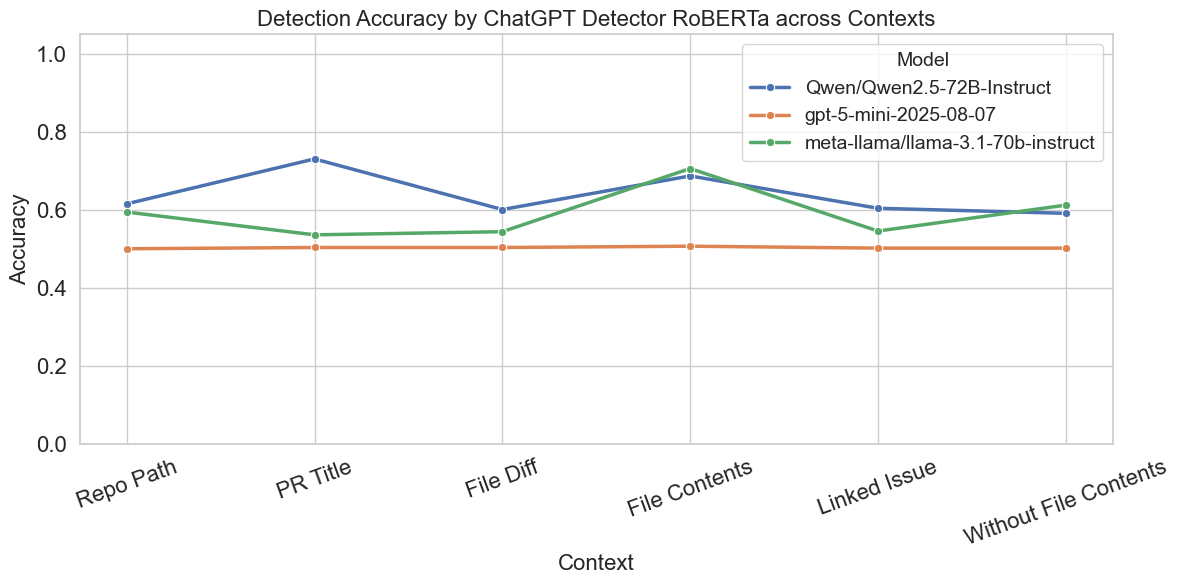

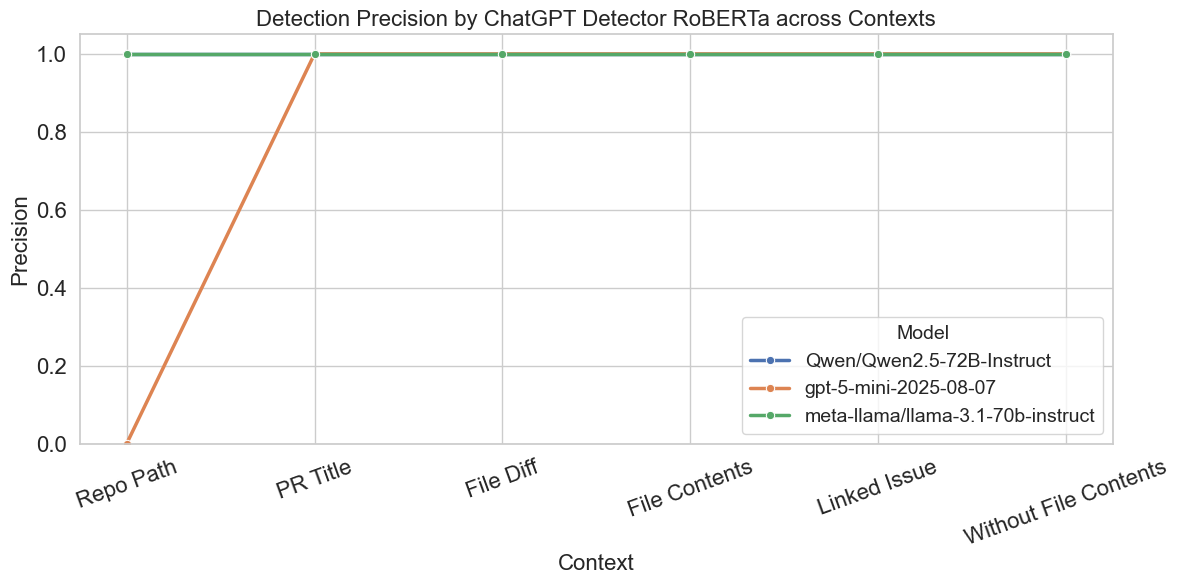

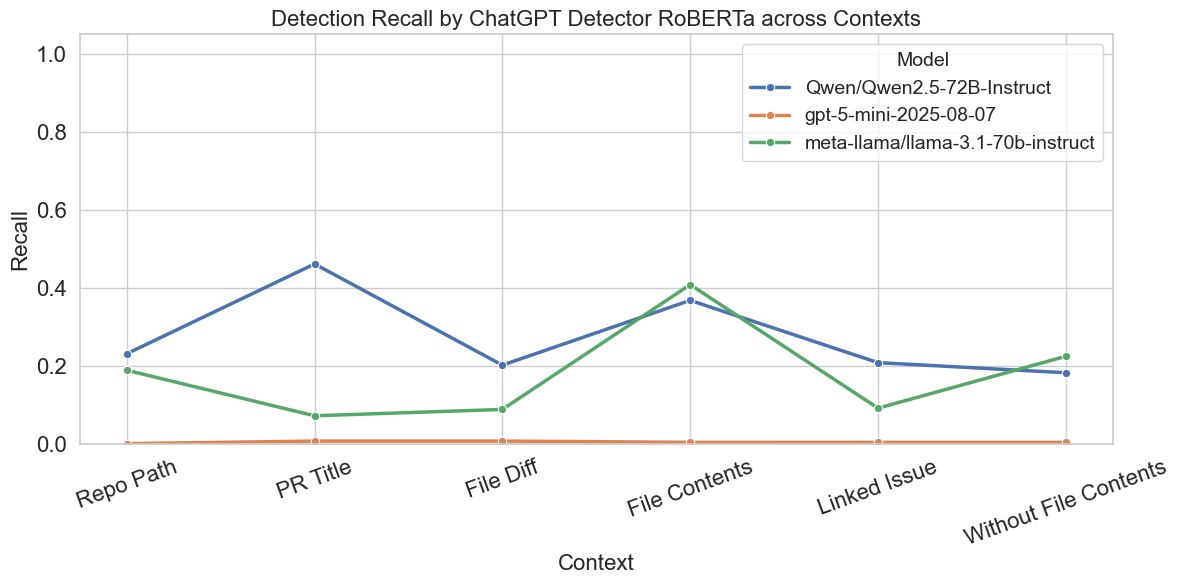

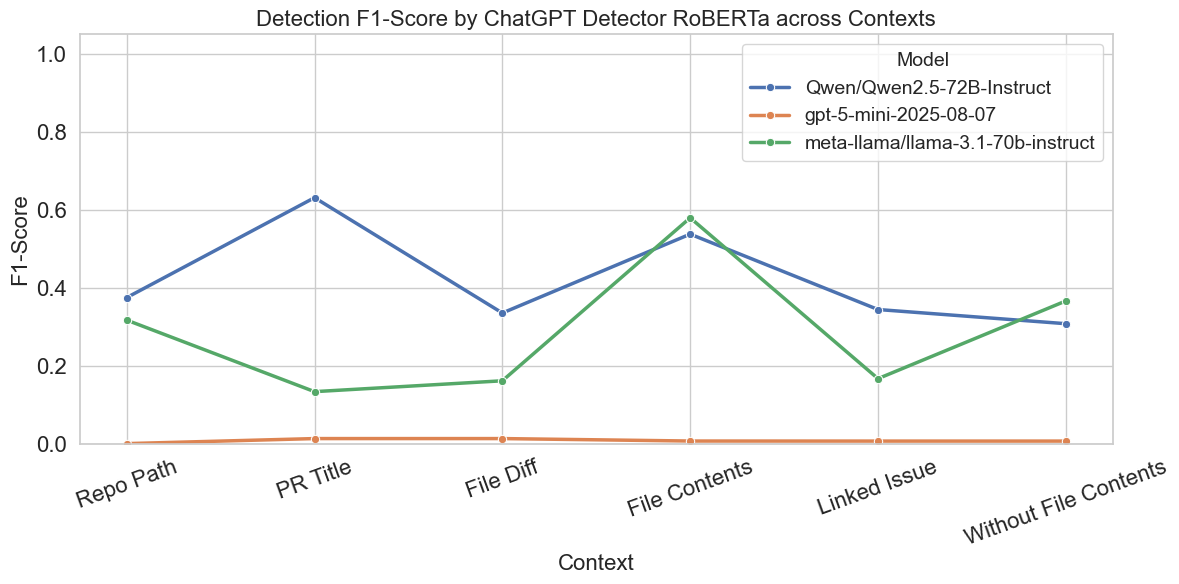

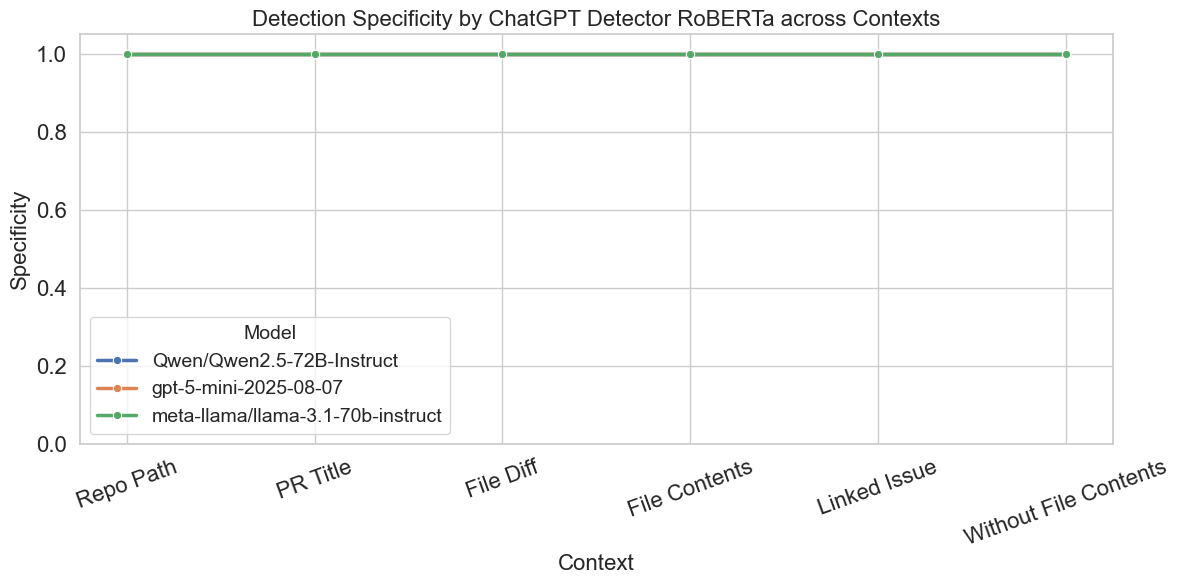

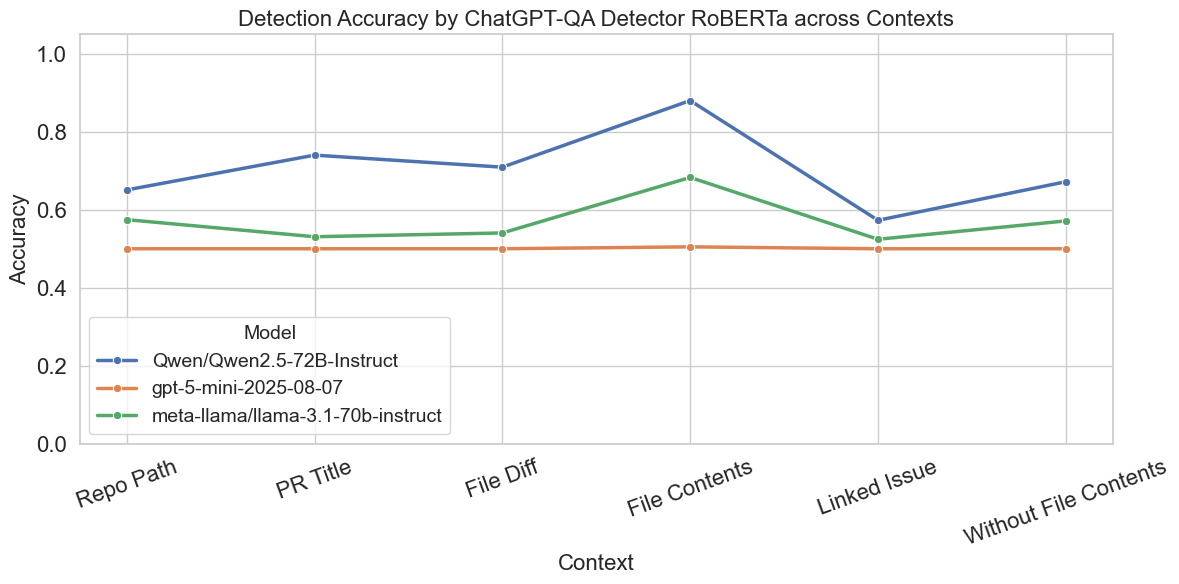

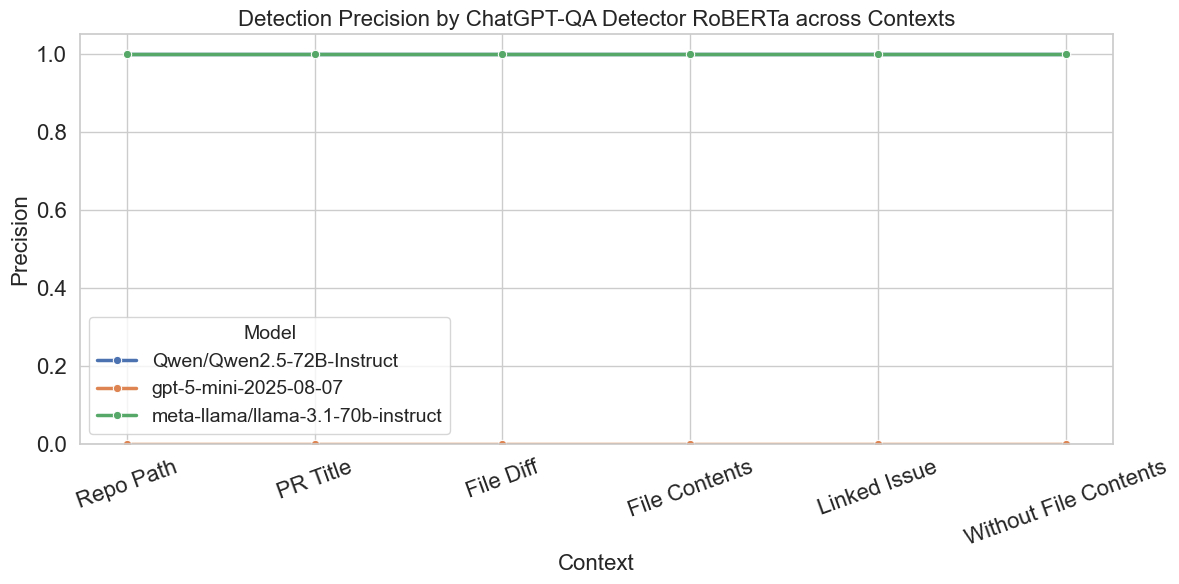

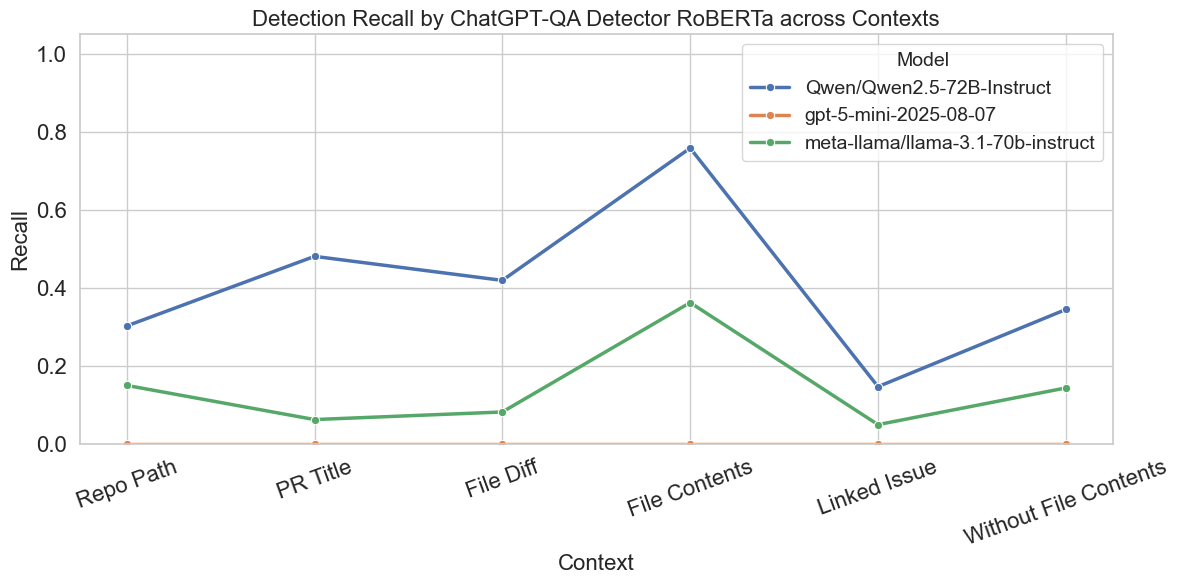

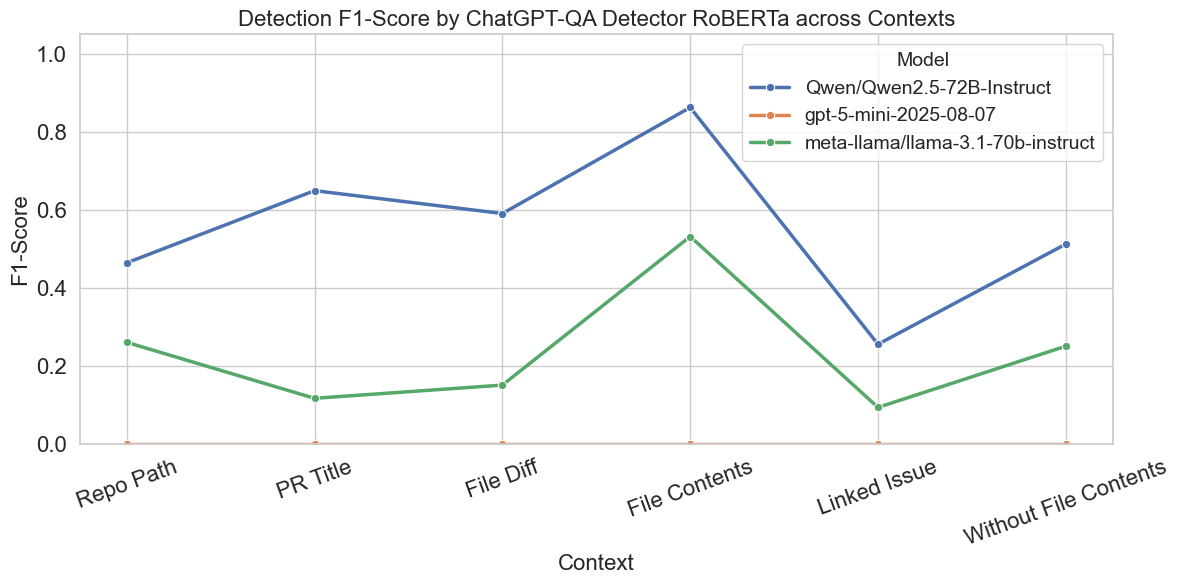

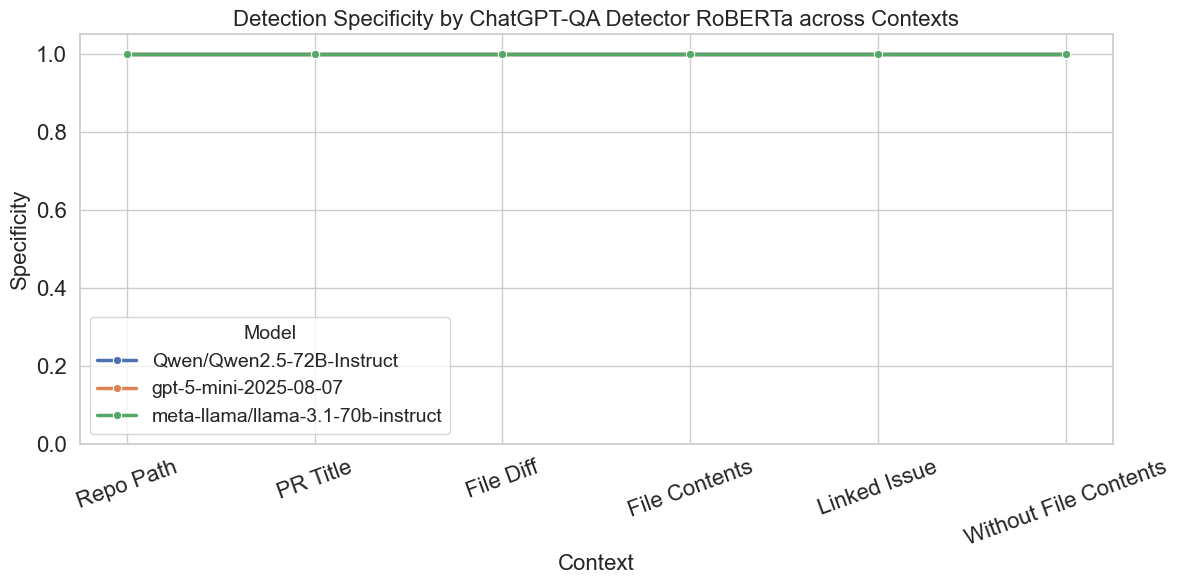

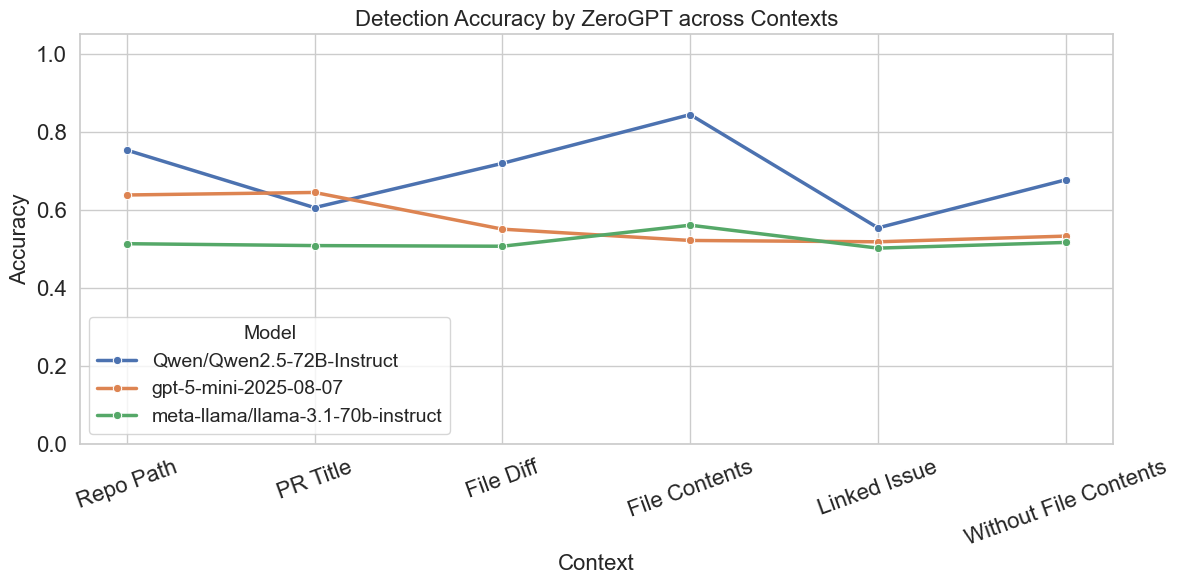

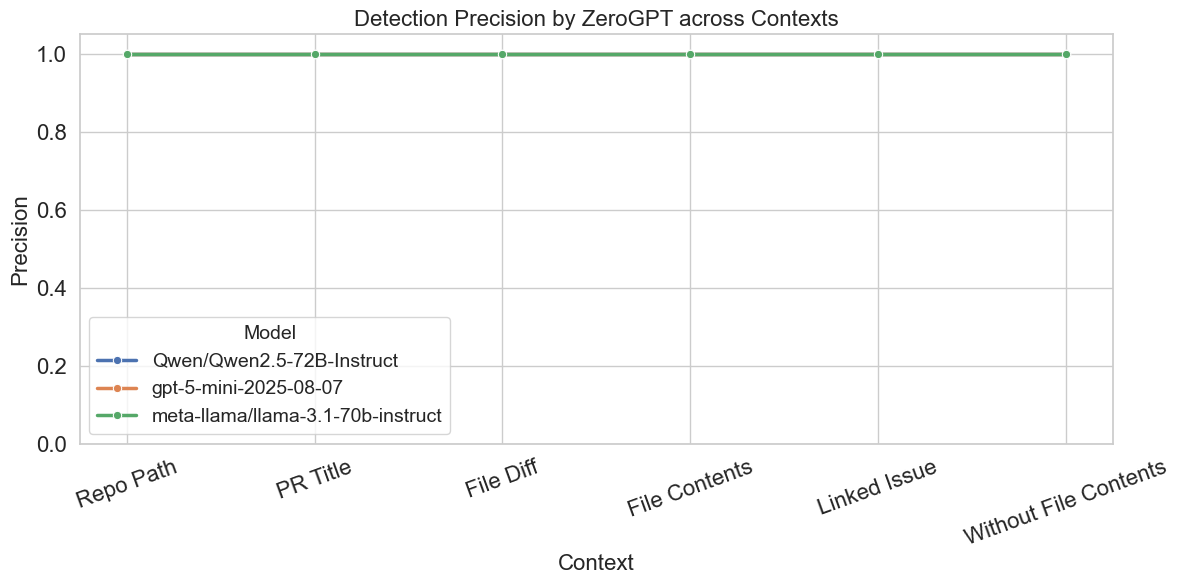

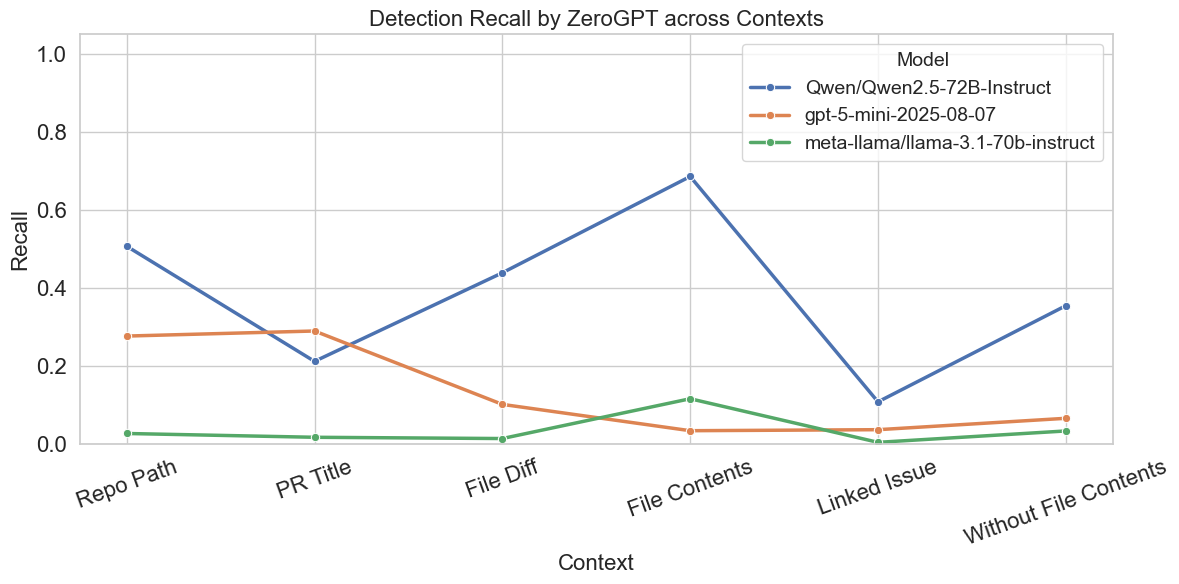

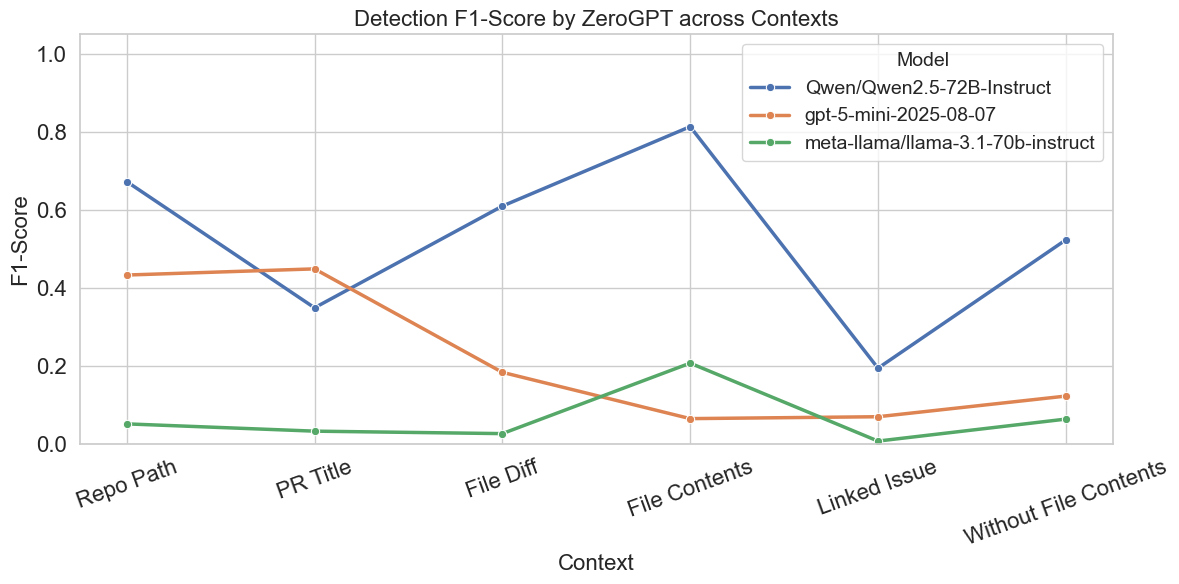

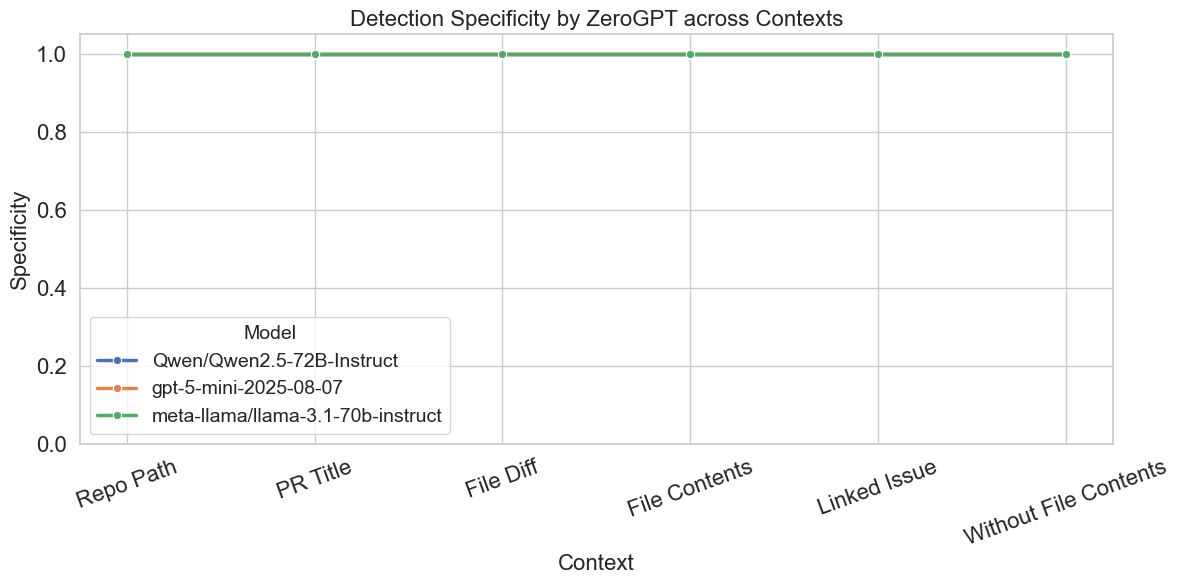


✅ Analysis complete.


In [9]:
variation_order = ["P-1", "P-2", "P-3", "P-4", "P-5", "P-6"]
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "Specificity"]

def get_tool_label(tool_name):
    if tool_name == "roberta":
        return "ChatGPT Detector RoBERTa"
    if tool_name == "roberta-qa":
        return "ChatGPT-QA Detector RoBERTa"
    if tool_name == "zerogpt":
        return "ZeroGPT"
for tool in tools:
    for metric in metrics_to_plot:
        plot_data = []
        for var_code in variation_order:
            for model in models:
                ai_data = ai_subset_full[
                    (ai_subset_full["variation"] == var_code)
                    & (ai_subset_full["model"] == model)
                ].copy()
                if ai_data.empty:
                    continue
                ai_data["true_label"] = 1
                combined = pd.concat([human_df, ai_data])
                
                # Calculate all metrics
                m = calculate_metrics(combined["true_label"], combined[f"{tool}_is_ai"])
                plot_data.append(
                    {"Context": variation_map[var_code], "Model": model, "Value": m[metric]}
                )

        if not plot_data:
            continue

        plt.figure(figsize=(12, 6))
        plot_df = pd.DataFrame(plot_data)
        sns.lineplot(
            data=plot_df,
            x="Context",
            y="Value",
            hue="Model",
            marker="o",
            linewidth=2.5,
        )
        plt.ylim(0, 1.05)
        plt.title(f"Detection {metric} by {get_tool_label(tool)} across Contexts", fontsize=16)
        plt.ylabel(metric, fontsize=16)
        plt.xlabel("Context", fontsize=16)
        plt.xticks(rotation=20, fontsize=16)
        plt.yticks(fontsize=16)
        plt.legend(title="Model", title_fontsize=14, fontsize=14)
        plt.tight_layout()
        plt.show()

print("\n✅ Analysis complete.")

## 3. RQ2: Contextual Impact Visualization (All Pairwise Comparisons)

This section visualizes the magnitude of differences between **ALL pairs** of context variations using Cliff's Delta.

- **Effect Size**: Cliff's Delta ($d$)
- **Interpretation**: 
  - $|d| < 0.147$: Negligible
  - $|d| < 0.33$: Small
  - $|d| < 0.474$: Medium
  - $|d| \ge 0.474$: Large
- **Chart Type**: Lollipop / Dot Plot

In [10]:
# --- Calculation of All Pairwise Cliff's Delta ---
import itertools

# Define all variations
all_vars = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
models = ai_subset_full['model'].unique()
tools = ['roberta', 'roberta-qa', 'zerogpt']

results = []

for tool in tools:
    prob_col = f'{tool}_ai_probability'
    if prob_col not in ai_subset_full.columns:
        prob_col = f'{tool}_is_ai'
        
    for model in models:
        # Generate all unique pairs
        for var_a, var_b in itertools.combinations(all_vars, 2):
            
            # Get Data for Var A
            data_a = ai_subset_full[
                (ai_subset_full['model'] == model) & 
                (ai_subset_full['variation'] == var_a)
            ][prob_col].dropna().tolist()
            
            # Get Data for Var B
            data_b = ai_subset_full[
                (ai_subset_full['model'] == model) & 
                (ai_subset_full['variation'] == var_b)
            ][prob_col].dropna().tolist()
            
            if not data_a or not data_b:
                continue
            
            # Calculate Cliff's Delta (A relative to B)
            d = cliffs_delta(data_a, data_b)
            mag = interpret_cliffs_delta(d)
            
            # For label, we use the mapped names
            name_a = variation_map.get(var_a, var_a)
            name_b = variation_map.get(var_b, var_b)
            
            results.append({
                'Detector': tool,
                'Model': model,
                'Comparison': f"{name_a} vs {name_b}",
                'VariationPair': f"{var_a}:{var_b}",
                'CliffsDelta': d,
                'Magnitude': mag
            })

results_df = pd.DataFrame(results)
print(f"Calculated {len(results_df)} pairwise effect sizes.")
display(results_df.head())

Calculated 135 pairwise effect sizes.


,Detector,Model,Comparison,VariationPair,CliffsDelta,Magnitude
0,roberta,meta-llama/llama-3.1-70b-instruct,Repo Path vs PR Title,P-1:P-2,-0.253698,Small
1,roberta,meta-llama/llama-3.1-70b-instruct,Repo Path vs File Diff,P-1:P-3,0.405815,Medium
2,roberta,meta-llama/llama-3.1-70b-instruct,Repo Path vs File Contents,P-1:P-4,-0.289904,Small
3,roberta,meta-llama/llama-3.1-70b-instruct,Repo Path vs Linked Issue,P-1:P-5,0.373482,Medium
4,roberta,meta-llama/llama-3.1-70b-instruct,Repo Path vs Without File Contents,P-1:P-6,0.297580,Small


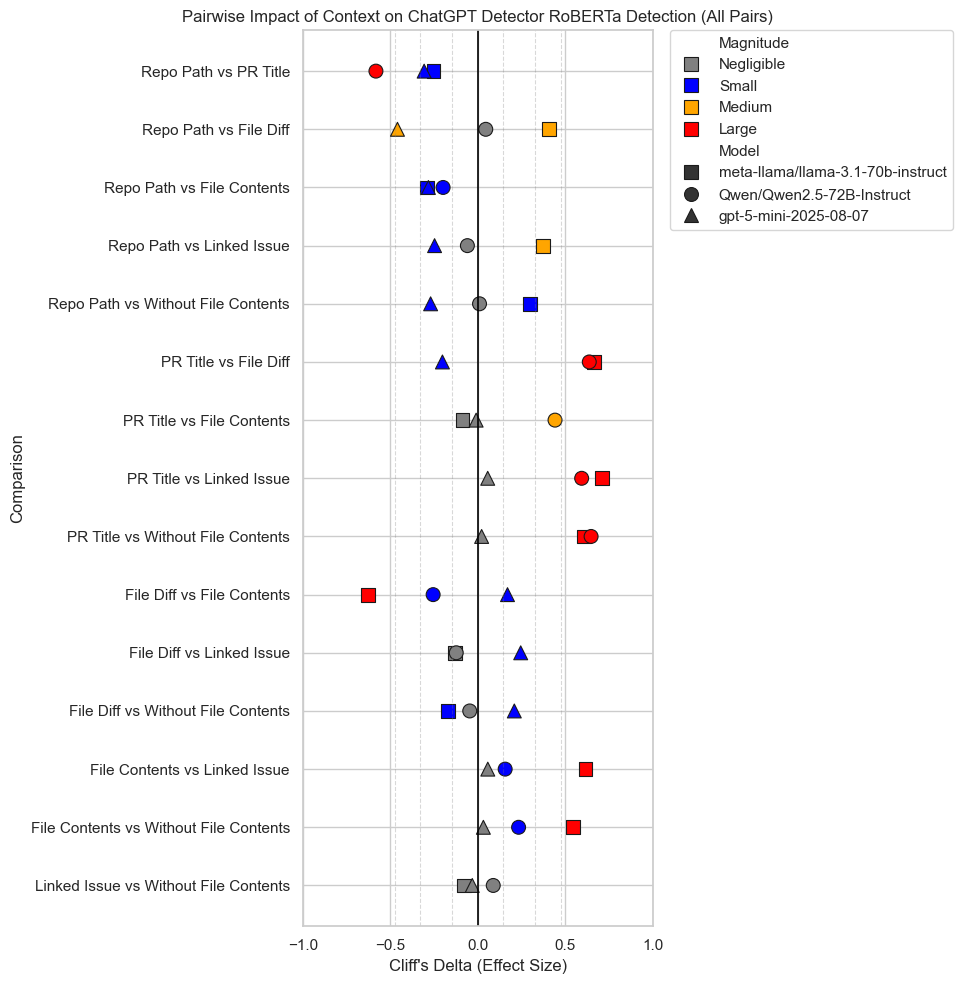

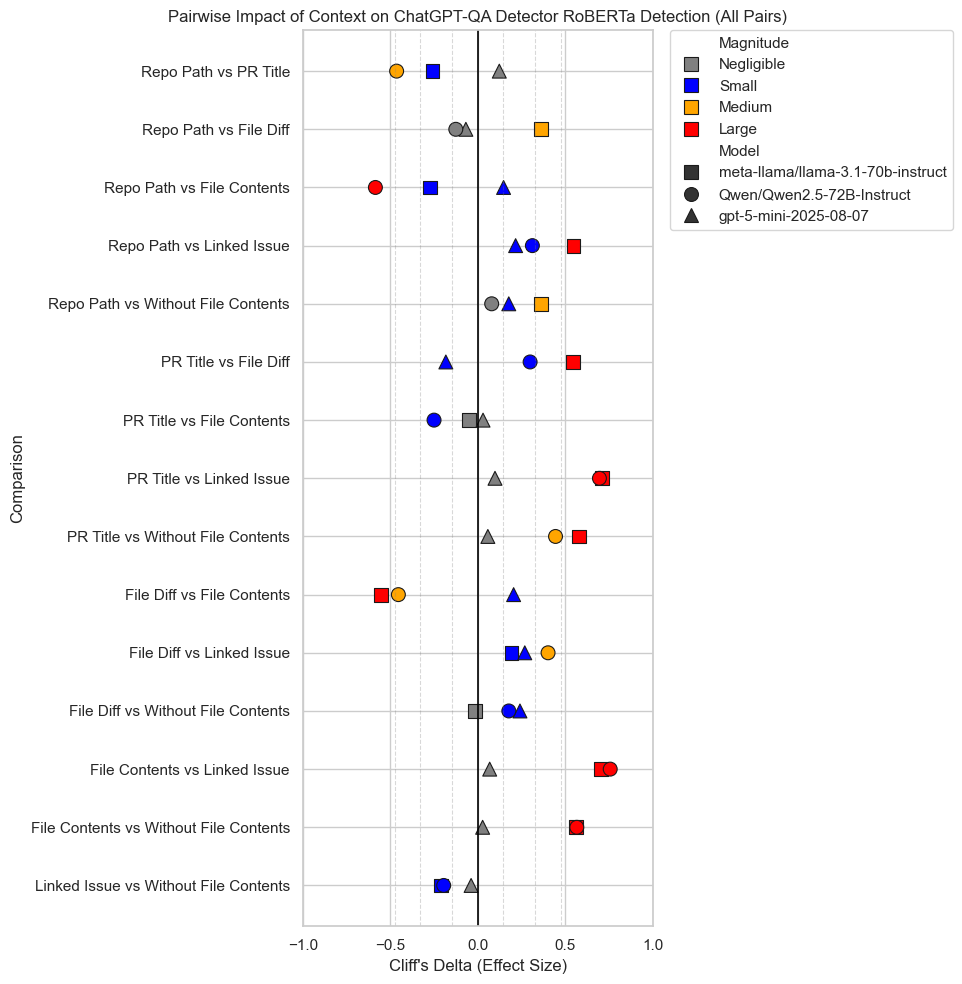

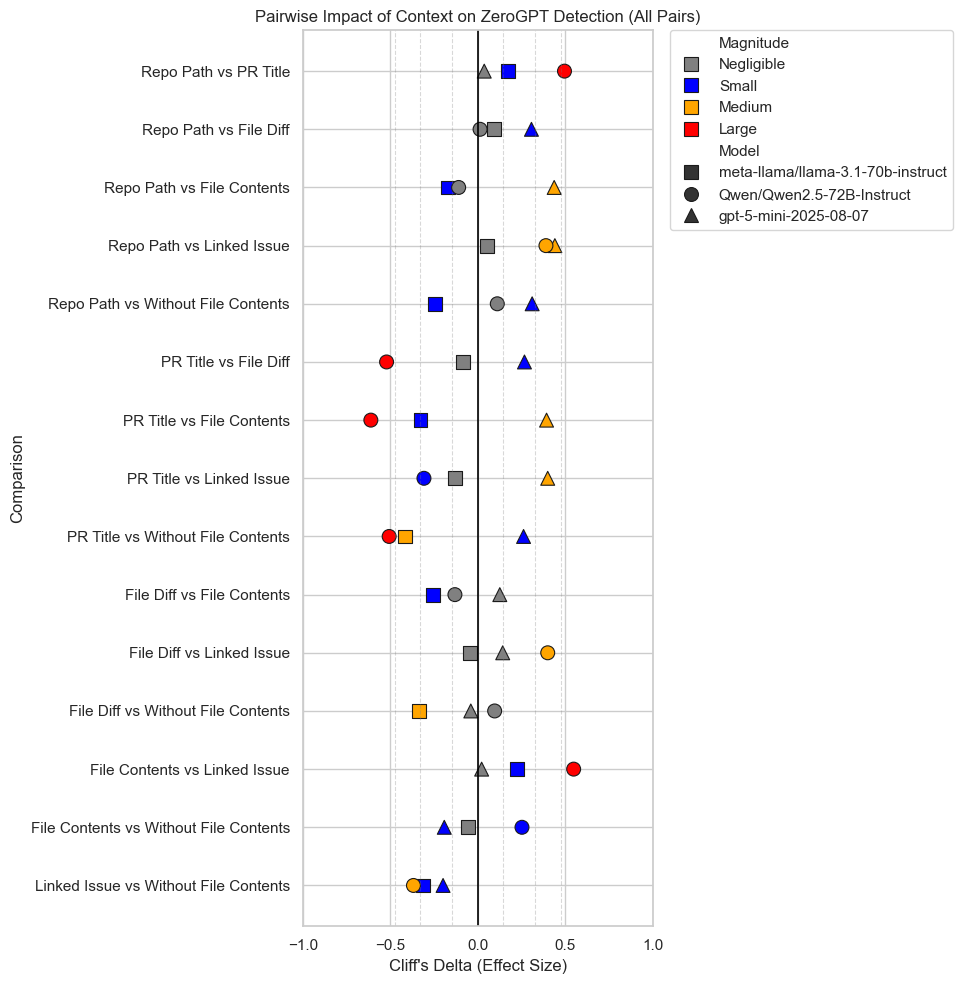

In [11]:
# --- Visualization: 3 Charts (One per Detector) ---

sns.set_theme(style="whitegrid")

magnitude_colors = {
    'Negligible': 'grey',
    'Small': 'blue',
    'Medium': 'orange',
    'Large': 'red'
}

model_markers = {
    'meta-llama/llama-3.1-70b-instruct': 's',       # Square
    'Qwen/Qwen2.5-72B-Instruct': 'o',              # Circle
    'gpt-5-mini-2025-08-07': '^'                   # Triangle
}

for tool in tools:
    subset = results_df[results_df['Detector'] == tool].copy()
    if subset.empty:
        continue
        
    # Sort Comparisons by absolute mean delta
    subset['abs_d'] = subset['CliffsDelta'].abs()
    order = subset.groupby('Comparison')['abs_d'].mean().sort_values(ascending=False).index
    
    # Adjust figure height based on number of comparisons
    # 15 pairs approx -> taller figure needed
    plt.figure(figsize=(10, 10))
    
    sns.scatterplot(
        data=subset,
        x='CliffsDelta',
        y='Comparison',
        hue='Magnitude',
        style='Model',
        palette=magnitude_colors,
        markers=model_markers,
        s=100,
        edgecolor='k',
        hue_order=['Negligible', 'Small', 'Medium', 'Large'],
        style_order=list(model_markers.keys())
    )
    
    # Vertical Threshold Lines
    for x in [-0.474, -0.33, -0.147, 0.147, 0.33, 0.474]:
        plt.axvline(x, color='gray', linestyle='--', alpha=0.3, linewidth=0.8)
    plt.axvline(0, color='black', linewidth=1.2)
    
    plt.xlim(-1.0, 1.0)
    plt.title(f"Pairwise Impact of Context on {get_tool_label(tool)} Detection (All Pairs)")
    plt.xlabel("Cliff's Delta (Effect Size)")
    plt.ylabel("Comparison")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
    
    plt.tight_layout()
    plt.show()

In [12]:
# --- Table of Effect Sizes ---

sorted_effects = results_df.sort_values(
    by='CliffsDelta', key=lambda x: x.abs(), ascending=False
)

print(f"\n>>> Pairs Effect Sizes ({len(sorted_effects)}):")

with pd.option_context('display.max_rows', 150):
    display(sorted_effects[['Detector', 'Model', 'Comparison', 'CliffsDelta', 'Magnitude']])


>>> Pairs Effect Sizes (135):


,Detector,Model,Comparison,CliffsDelta,Magnitude
87,roberta-qa,Qwen/Qwen2.5-72B-Instruct,File Contents vs Linked Issue,0.757961,Large
7,roberta,meta-llama/llama-3.1-70b-instruct,PR Title vs Linked Issue,0.712551,Large
52,roberta-qa,meta-llama/llama-3.1-70b-instruct,PR Title vs Linked Issue,0.710020,Large
57,roberta-qa,meta-llama/llama-3.1-70b-instruct,File Contents vs Linked Issue,0.706433,Large
82,roberta-qa,Qwen/Qwen2.5-72B-Instruct,PR Title vs Linked Issue,0.696272,Large
5,roberta,meta-llama/llama-3.1-70b-instruct,PR Title vs File Diff,0.666869,Large
38,roberta,Qwen/Qwen2.5-72B-Instruct,PR Title vs Without File Contents,0.648485,Large
35,roberta,Qwen/Qwen2.5-72B-Instruct,PR Title vs File Diff,0.638107,Large
9,roberta,meta-llama/llama-3.1-70b-instruct,File Diff vs File Contents,-0.628696,Large
12,roberta,meta-llama/llama-3.1-70b-instruct,File Contents vs Linked Issue,0.616520,Large
